In [1]:
%pip install pandas numpy matplotlib scikit-learn
import pandas as pd
import matplotlib.pyplot as plt
df= pd.read_csv("housing.csv")
df.head()



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [2]:
import pandas as pd
df =pd.read_csv("housing.csv")
df.head(503)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY
...,...,...,...,...,...,...,...,...,...,...
498,-122.27,37.85,47.0,2077.0,400.0,719.0,326.0,2.2431,172700.0,NEAR BAY
499,-122.27,37.85,50.0,1279.0,300.0,675.0,255.0,1.9028,150800.0,NEAR BAY
500,-122.27,37.85,52.0,1974.0,426.0,875.0,363.0,1.5817,153600.0,NEAR BAY
501,-122.27,37.85,52.0,335.0,83.0,152.0,77.0,2.2841,106300.0,NEAR BAY


In [3]:
df.info()



<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB


In [4]:
df.isnull().sum()

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

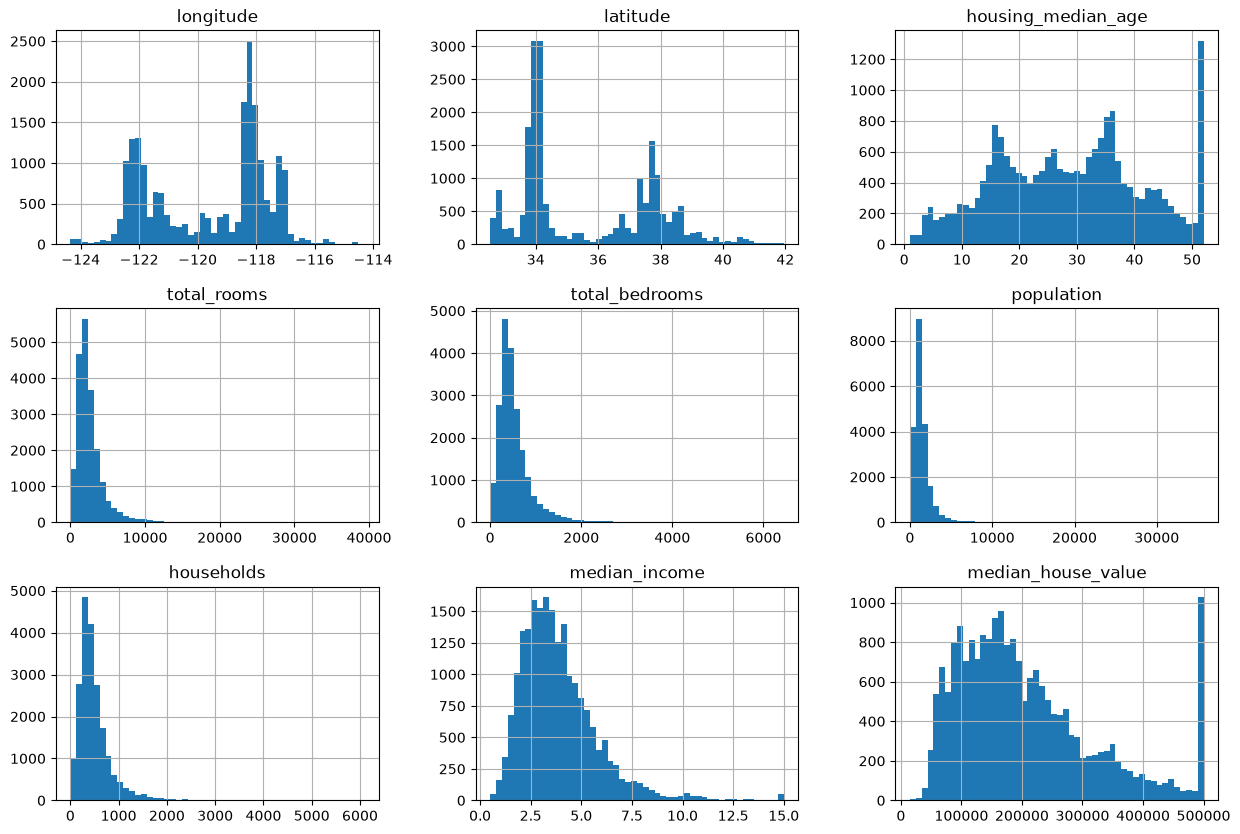

In [8]:
df.hist(bins=50,figsize=(15,10))
plt.show()


In [5]:
print((df["median_house_value"]==500001).sum())

965


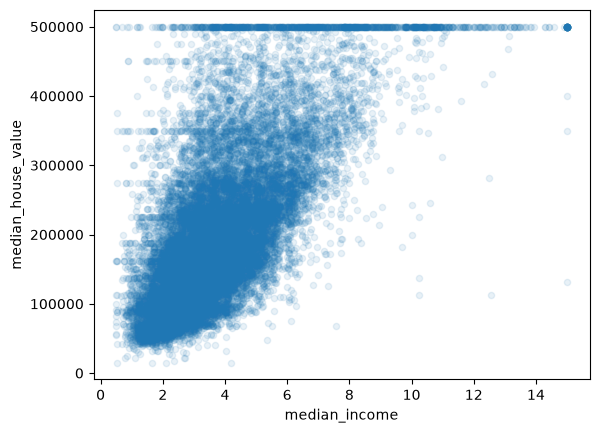

In [6]:
df.plot(kind="scatter", x="median_income", y="median_house_value", alpha=0.1)
plt.show()

In [7]:
# the goal of whole cell
# training set(80%) the model run from these rows
# test set(20)hidden untill it run used to check the model on houses it has never seen
# idx is a shuffled list of row numbers Why shuffle at all? The CSV file might be sorted, for example by location. If you simply took the last 20% as the test set, it might contain only one region, and your test would be unfair. Shuffling mixes everything.
# df.iloc means picks rows from df by their position and .copy make seperte copy of tables
# 
import numpy as np
np.random.seed(42)
idx=np.random.permutation(len(df))
split=int(0.8*len(df))

train_set=df.iloc[idx[:split]].copy()
test_set=df.iloc[idx[split:]].copy()

print(len(train_set),len(test_set))


16512 4128


In [8]:
# The test set is supposed to be “houses the model has never seen”. 
# If you calculated the median using test rows too, information from the test set would leak into your preparation, 
# and your final score would look slightly better than it truly is. 
median_bed = train_set["total_bedrooms"].median()
print(median_bed)

train_set["total_bedrooms"] = train_set["total_bedrooms"].fillna(median_bed)
test_set["total_bedrooms"] = test_set["total_bedrooms"].fillna(median_bed)

print(train_set["total_bedrooms"].isnull().sum())
print(test_set["total_bedrooms"].isnull().sum())

433.0
0
0


In [9]:
# scaling
# 0 means “exactly average”, +1 means “one std above average”, and -1 means “one std below”.
x_train=train_set["median_income"].values
y_train=train_set["median_house_value"].values
x_mean,x_std = x_train.mean(),x_train.std()
y_mean,y_std = y_train.mean(),y_train.std()
x_s=(x_train-x_mean)/x_std
y_s=(y_train-y_mean)/y_std
print(x_s.mean(),y_s.mean())
print(x_s.std(),y_s.std())

# mean comes out to be zero and std comes out to be 1 std means out our data spread out



2.7809365490853e-17 -5.163828021512356e-17
1.0 1.0


Iteration 0, Cost=0.4548
Iteration 50, Cost=0.2621
0.6897332357258767 -6.127473636151877e-17


Text(0, 0.5, 'cost')

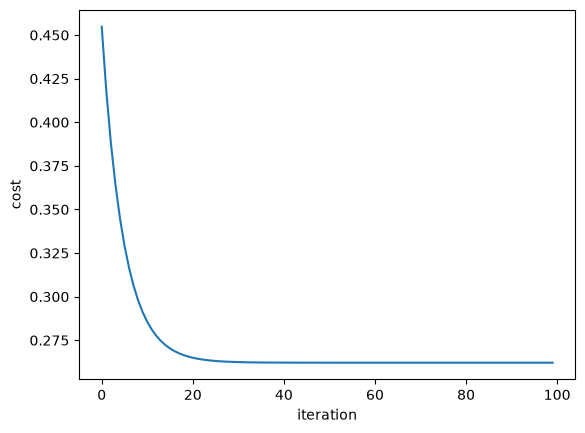

In [10]:
# cost function
def calc_cost(x,y,w,b):
    m = x.shape[0]
    total=0
    for i in range (m):
        total+=(w*x[i]+b-y[i])**2
    return total/(2*m)
# print(calc_cost(np.array([1,2,3]),np.array([2,4,6]),0,0))

# gradient
def gradient(x,y,w,b):
    m=x.shape[0]
    dj_dw_in=0
    dj_db_in=0
    for i in range(m):
        f_wb=w*x[i]+b
        dj_dw_in+= (f_wb-y[i])*x[i]
        dj_db_in+=(f_wb-y[i])
    return dj_dw_in/m,dj_db_in/m
# print(gradient(np.array([1,2,3]),np.array([2,4,6]),0,0))    

# gradient descent
def gradient_descent(x,y,w_in,b_in,alpha,itr):
    cost_hist=[]
    w,b=w_in,b_in
    for i in range(itr):
       dj_dw, dj_db = gradient(x, y, w, b)
       w=w-alpha*dj_dw
       b=b-alpha*dj_db
       cost_hist.append(calc_cost(x,y,w,b))
       if i % 50 == 0:
            print(f"Iteration {i}, Cost={cost_hist[-1]:.4f}")
    return w, b, cost_hist

w, b, c = gradient_descent(x_s, y_s, 0, 0, 0.1, 100)
print(w, b)
plt.plot(c)
plt.xlabel("iteration")
plt.ylabel("cost")



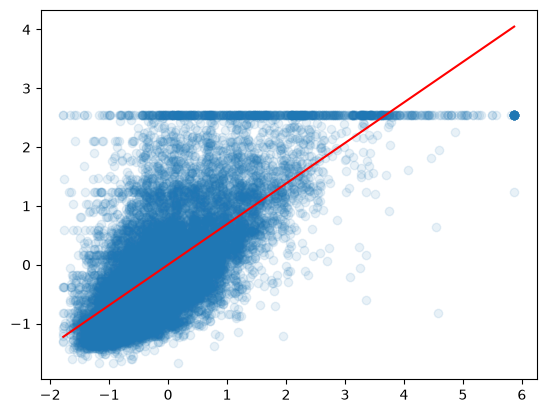

In [11]:
plt.scatter(x_s, y_s, alpha=0.1)
x_line = np.array([x_s.min(), x_s.max()])
plt.plot(x_line, w * x_line + b, color="red")
plt.show()

RMSE: 84913.98972540465
R2: 0.4643050972775853
Baseline RMSE: 116017.42731479966


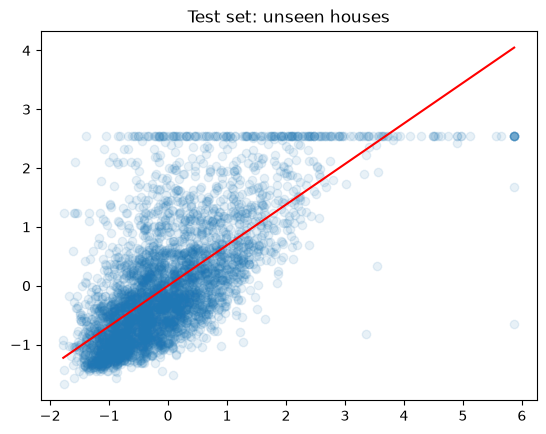

In [12]:
x_test = test_set["median_income"].values
y_test = test_set["median_house_value"].values

x_test_s = (x_test - x_mean) / x_std
pred = (w * x_test_s + b) * y_std + y_mean

rmse = np.sqrt(np.mean((pred - y_test) ** 2))

ss_res = np.sum((y_test - pred) ** 2)
ss_tot = np.sum((y_test - y_test.mean()) ** 2)
r2 = 1 - ss_res / ss_tot

baseline = np.sqrt(np.mean((y_train.mean() - y_test) ** 2))

print("RMSE:", rmse)
print("R2:", r2)
print("Baseline RMSE:", baseline)

plt.scatter(x_test_s, (y_test - y_mean) / y_std, alpha=0.1)
x_line = np.array([x_test_s.min(), x_test_s.max()])
plt.plot(x_line, w * x_line + b, color="red")
plt.title("Test set: unseen houses")
plt.show()

